# 3.1 One-way slab: simply supported

A stand-alone example: a corridor slab on two parallel walls.

**Workflow**

| Step | Check | Reference |
|:--|:--|:--|
| 1 | One-way or two-way: ly/lx > 2 → one-way | EC2 5.3.1(5) |
| 2 | Thickness, cover, effective depth, fire | EC2 4.4.1, EN 1992-1-2 |
| 3 | Actions and ULS combination | EN 1990, EN 1991-1-1 |
| 4 | Moments and shears | EC2 5; coefficients |
| 5 | Bending steel, minimum and maximum | EC2 6.1, 9.2.1.1, 9.3.1.1 |
| 6 | Shear without links | EC2 6.2.2 |
| 7 | Deflection | EC2 7.4.2 |
| 8 | Cracking, spacing, secondary steel, curtailment | EC2 7.3.3, 9.3.1 |

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

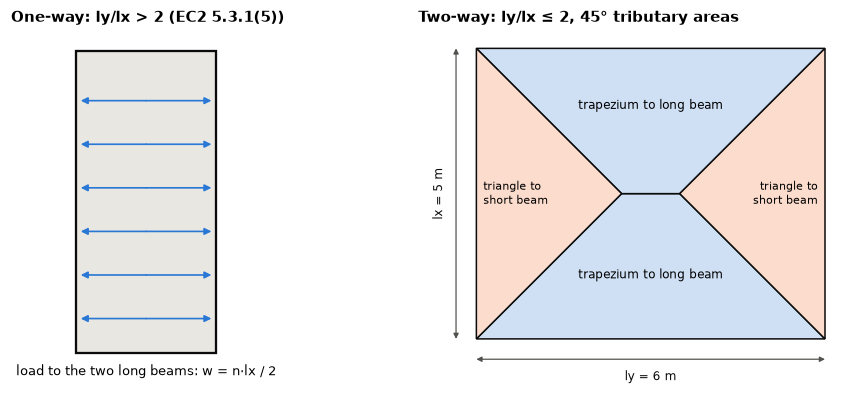

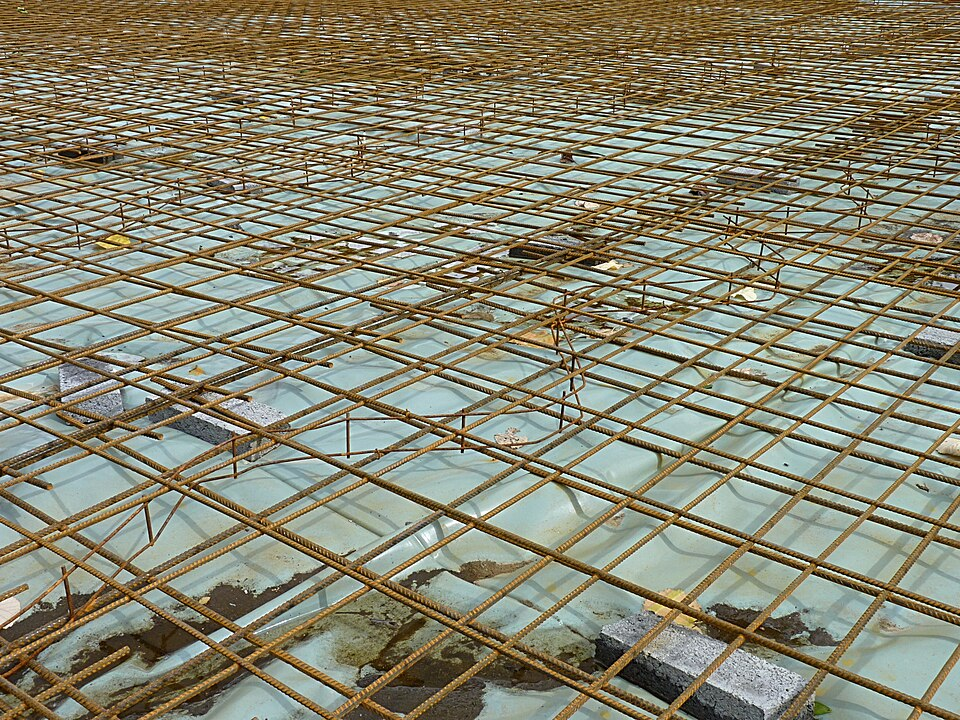

*Two-directional slab reinforcement before casting. Main bars and secondary bars cross at right angles.* <br><small>Photo: Jamain, [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0), via [Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Steel_reinforcement_J1a.JPG).</small>

In [2]:
P.sketch_slab_load()
photo("slab_j1a", "Two-directional slab reinforcement before casting. Main bars and secondary bars cross at right angles.")

## Inputs

## Effective span and depth

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `ln`, `t` | Clear span; bearing width of each wall | m; mm | > 0 |
| `h` | Slab thickness | mm | > 0 |
| `exposure` | Exposure class |  | `"X0"`, `"XC1"` to `"XC4"`, `"XD1"` to `"XD3"`, `"XS1"` to `"XS3"` |
| `R` | Fire rating | minutes | 30, 60, 90, 120, 180, 240 |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |
| `phi`, `spacing` | Main bars to verify | mm | 8, 10, 12, 16, 20, 25, 32 |
| `finishes`, `qk`, `part` | Finishes, imposed load, partitions (characteristic) | kN/m² | self-weight is added for you |
| `psi2` | Quasi-permanent factor |  | 0.3 for homes and offices |

In [3]:
# INPUTS: edit only this cell, then run the cells below it
ln, t = 3.60, 300            # clear span (m), bearing width of each wall (mm)
h, exposure, R = 150, "XC1", 60
fck, fyk = 30, 500           # N/mm²
phi, spacing = 12, 200       # main bars to be verified
finishes, qk, part, psi2 = 1.5, 3.0, 0.8, 0.3

In [4]:
s = Sheet("Simply supported one-way slab", element=f"Corridor slab, {ln} m clear")
D.materials(s, fck, fyk, BRIEF["ndp"])
D.floor_actions(s, h, finishes, qk, part); s.show("Actions")
c = D.cover(s, exposure, phi)

## Simply supported one-way slab

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Corridor slab, 3.6 m clear

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Actions

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Slab thickness: $h$ | $h = 150$ mm |
| EN 1991-1-1 Table A.1 | Reinforced concrete, 24 + 1: $\gamma_{rc}$ | $\gamma_{rc} = 25$ kN/m³ |
| EN 1991-1-1 5.2 | $g_{k,self} = \dfrac{\gamma_{rc}\,h}{1000}$<br>$\quad = \dfrac{25\times 150}{1000}$ | $\mathbf{g_{k,self} = 3.75}$ kN/m²<br><small>(= 3750 Pa)</small> |
|  | Finishes and services (project input): $g_{k,fin}$ | $g_{k,fin} = 1.5$ kN/m²<br><small>(= 1500 Pa)</small> |
|  | $g_{k} = g_{k,self} + g_{k,fin}$<br>$\quad = 3.75 + 1.5$ | $\mathbf{g_{k} = 5.25}$ kN/m²<br><small>(= 5250 Pa)</small> |
| EN 1991-1-1 Table 6.2 | Imposed load, category B: $q_{k,1}$ | $q_{k,1} = 3$ kN/m²<br><small>(= 3000 Pa)</small> |
| EN 1991-1-1 6.3.1.2(8) | Movable partitions (1.0 to 2.0 kN/m wall): $q_{k,2}$ | $q_{k,2} = 0.8$ kN/m²<br><small>(= 800 Pa)</small> |
|  | $q_{k} = q_{k,1} + q_{k,2}$<br>$\quad = 3 + 0.8$ | $\mathbf{q_{k} = 3.8}$ kN/m²<br><small>(= 3800 Pa)</small> |
| EN 1990 Table A1.2(B) | $\gamma_{G}$ | $\gamma_{G} = 1.35$  |
| EN 1990 Table A1.2(B) | $\gamma_{Q}$ | $\gamma_{Q} = 1.5$  |
| EN 1990 Exp. (6.10) | $n_{Ed} = \gamma_{G}\,g_{k} + \gamma_{Q}\,q_{k}$<br>$\quad = 1.35\times 5.25 + 1.5\times 3.8$ | $\mathbf{n_{Ed} = 12.79}$ kN/m²<br><small>(= 12788 Pa)</small> |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 12$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
| EC2 Exp. (4.1), (4.2) | $c_{req} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{12;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


In [5]:
s.let("l_n", ln * 1000, "mm", "Clear span"); s.let("t", t, "mm", "Bearing width"); s.let("phi", phi, "mm")
s.calc("a_1", "min(h/2, t/2)", "mm", "EC2 5.3.2.2, Fig. 5.4(a)")
s.calc("l_eff", "l_n + 2*a_1", "mm", "EC2 Exp. (5.8)")
s.calc("d", "h - c_nom - phi/2", "mm", "", "Effective depth")
s.show()
D.fire_slab(s, R, h, c + phi / 2)

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Clear span: $l_{n}$ | $l_{n} = 3600$ mm |
|  | Bearing width: $t$ | $t = 300$ mm |
| EC2 5.3.2.2, Fig. 5.4(a) | $a_{1} = \min\left\{\dfrac{h}{2};\; \dfrac{t}{2}\right\}$<br>$\quad = \min\left\{\dfrac{150}{2};\; \dfrac{300}{2}\right\}$ | $\mathbf{a_{1} = 75}$ mm |
| EC2 Exp. (5.8) | $l_{eff} = l_{n} + 2\,a_{1}$<br>$\quad = 3600 + 2\times 75$ | $\mathbf{l_{eff} = 3750}$ mm |
|  | Effective depth<br>$d = h - c_{nom} - \dfrac{\phi}{2}$<br>$\quad = 150 - 25 - \dfrac{12}{2}$ | $\mathbf{d = 119}$ mm |


### Fire resistance

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Axis distance to the lower bar: $a_{prov}$ | $a_{prov} = 31$ mm |
| EN 1992-1-2 Table 5.8 | REI 60: $a_{req}$ | $a_{req} = 20$ mm |
| EN 1992-1-2 Table 5.8 | REI 60: $h_{s,min}$ | $h_{s,min} = 80$ mm |
| EN 1992-1-2 5.7 | **Check:** fire – slab thickness<br>$h = 150 \ge h_{s,min} = 80$ mm | ✅ **PASS**<br>ratio 0.53 |
| EN 1992-1-2 5.7 | **Check:** fire – axis distance<br>$a_{prov} = 31 \ge a_{req} = 20$ mm | ✅ **PASS**<br>ratio 0.65 |


## Analysis and bending

### Moments and shears (1 m strip)

| Reference | Calculation | Output |
|:--|:--|:--|
| Notebook 1.1 | $M_{span} = \dfrac{n_{Ed}\,\left(\dfrac{l_{eff}}{1000}\right)^{2}}{8}$<br>$\quad = \dfrac{12.79\times \left(\dfrac{3750}{1000}\right)^{2}}{8}$ | $\mathbf{M_{span} = 22.48}$ kN·m/m |
| Notebook 1.1 | $V_{sup} = \dfrac{\dfrac{n_{Ed}\,l_{eff}}{1000}}{2}$<br>$\quad = \dfrac{\dfrac{12.79\times 3750}{1000}}{2}$ | $\mathbf{V_{sup} = 23.98}$ kN/m |


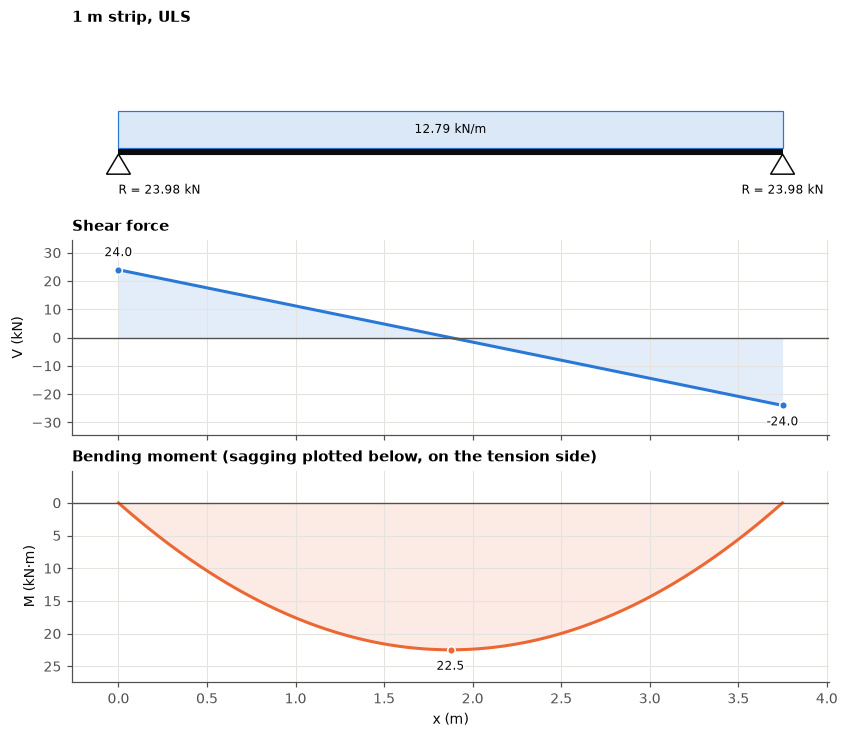

### Bending at mid-span

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 Exp. (3.21) | Stress-block strength factor, fck ≤ 50: $\eta$ | $\eta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | Design moment: $M_{Ed}$ | $M_{Ed} = 22.48$ kN·m |
|  | $b$ | $b = 1000$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{22.48\times 10^{6}}{1000\times 119^{2}\times 30}$ | $\mathbf{K = 0.05291}$ |
| EC2 5.5(4) | **Check:** singly reinforced<br>$K = 0.05291 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.32 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{119}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.05291\times 30}{1\times 17}}\right);\; 0.95\times 119\right\}$ | $\mathbf{z = 113}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(119 - 113\right)}{0.8}$ | $\mathbf{x = 14.88}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{22.48\times 10^{6}}{434.8\times 113}$ | $\mathbf{A_{s,req} = 457.3}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 1000$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 1000\times 119;\; 0.0013\times 1000\times 119\right\}$ | $\mathbf{A_{s,min} = 179.2}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{457.3;\; 179.2\right\}$ | $\mathbf{A_{s,req} = 457.3}$ mm² |


### Main reinforcement

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Spacing: $s_{prov}$ | $s_{prov} = 200$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 12^{2}}{4}\times 1000}{200}$ | $\mathbf{A_{s,prov} = 565.5}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided main bottom<br>$A_{s,prov} = 565.5 \ge A_{s,req} = 457.3$ mm²/m | ✅ **PASS**<br>ratio 0.81 |
| EC2 9.3.1.1(3) | Principal bars, zone of maximum moment: $s_{max}$ | $s_{max} = 250$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing main bottom<br>$s_{prov} = 200 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 0.80 |
| EC2 9.2.1.1(3) | $A_{s,max} = 0.04\times 1000\,h$<br>$\quad = 0.04\times 1000\times 150$ | $\mathbf{A_{s,max} = 6000}$ mm²/m |
| EC2 9.2.1.1(3) | **Check:** maximum steel main bottom<br>$A_{s,prov} = 565.5 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.09 |
|  | **PROVIDE: H12 @ 200 mm main bottom (565 mm²/m)** | 🟦 **H12 @ 200 mm main bottom (565 mm²/m)** |


In [6]:
s.calc("M_span", "n_Ed*(l_eff/1000)**2/8", "kN·m/m", "Notebook 1.1")
s.calc("V_sup", "n_Ed*l_eff/1000/2", "kN/m", "Notebook 1.1"); s.show("Moments and shears (1 m strip)")
P.determinate(DeterminateBeam(s["l_eff"] / 1000, [UDL(s["n_Ed"])], supports=(0, s["l_eff"] / 1000)), "1 m strip, ULS")
As, _ = D.flexure(s, s["M_span"], 1000, s["d"]); s.show("Bending at mid-span")
Ap = D.slab_bars(s, phi, spacing, h, label="main bottom"); s.show("Main reinforcement")

## Shear, deflection, cracking

In [7]:
d = s["d"]
D.shear_slab(s, s["V_sup"], d, Ap / 2); s.note("Only half the span steel is taken as anchored at the support (EC2 9.3.1.2(1)). Shear is taken at the support centre-line, which is conservative."); s.show("Shear")
D.deflection(s, s["l_eff"], d, 1000, As, Ap, "simply supported"); s.show("Deflection")
D.crack(s, s["g_k"], s["q_k"], psi2, As, Ap, spacing, h, n_uls="slab"); s.show("Cracking")

### Shear

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design shear: $V_{Ed}$ | $V_{Ed} = 23.98$ kN/m |
|  | $b_{w}$ | $b_{w} = 1000$ mm |
| EC2 Fig. 6.3 | Anchored tension steel: $A_{sl}$ | $A_{sl} = 282.7$ mm² |
| EC2 6.2.2(1), NA | $C_{Rd,c} = \dfrac{0.18}{\gamma_{c}}$<br>$\quad = \dfrac{0.18}{1.5}$ | $\mathbf{C_{Rd,c} = 0.12}$ |
| EC2 6.2.2(1) | $k = \min\left\{1 + \sqrt{\dfrac{200}{d}};\; 2\right\}$<br>$\quad = \min\left\{1 + \sqrt{\dfrac{200}{119}};\; 2\right\}$ | $\mathbf{k = 2}$ |
| EC2 6.2.2(1) | $\rho_{l} = \min\left\{\dfrac{A_{sl}}{b_{w}\,d};\; 0.02\right\}$<br>$\quad = \min\left\{\dfrac{282.7}{1000\times 119};\; 0.02\right\}$ | $\mathbf{\rho_{l} = 0.00238}$ |
| EC2 Exp. (6.3N) | $v_{min} = 0.035\,k^{1.5}\,\sqrt{f_{ck}}$<br>$\quad = 0.035\times 2^{1.5}\times \sqrt{30}$ | $\mathbf{v_{min} = 0.542}$ N/mm²<br><small>(= 0.542 MPa)</small> |
| EC2 Exp. (6.2a), (6.2b) | $V_{Rd,c} = \dfrac{\max\left\{C_{Rd,c}\,k\,\left(100\,\rho_{l}\,f_{ck}\right)^{1/3};\; v_{min}\right\}\,b_{w}\,d}{1000}$<br>$\quad = \dfrac{\max\left\{0.12\times 2\times \left(100\times 0.00238\times 30\right)^{1/3};\; 0.542\right\}\times 1000\times 119}{1000}$ | $\mathbf{V_{Rd,c} = 64.52}$ kN |
| EC2 6.2.1(3), 6.2.1(4) | **Check:** shear, no links needed<br>$V_{Ed} = 23.98 \le V_{Rd,c} = 64.52$ kN/m | ✅ **PASS**<br>ratio 0.37 |
|  | Only half the span steel is taken as anchored at the support (EC2 9.3.1.2(1)). Shear is taken at the support centre-line, which is conservative. |  |


### Deflection

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 7.4N / NA.5 | Structural system: simply supported: $K_{sys}$ | $K_{sys} = 1$  |
| EC2 7.4.2(2) | 10⁻³ √fck: $\rho_{0}$ | $\rho_{0} = 0.00548$  |
|  | Steel required for ULS at mid-span: $A_{s,ult}$ | $A_{s,ult} = 457.3$ mm² |
| EC2 7.4.2(2) | $\rho = \dfrac{A_{s,ult}}{b\,d}$<br>$\quad = \dfrac{457.3}{1000\times 119}$ | $\mathbf{\rho = 0.00384}$ |
| EC2 Exp. (7.16a) | Basic l/d<br>$N_{basic} = K_{sys}\,\left(11 + \dfrac{1.5\,\sqrt{f_{ck}}\,\rho_{0}}{\rho} + 3.2\,\sqrt{f_{ck}}\,\left(\dfrac{\rho_{0}}{\rho} - 1\right)^{1.5}\right)$<br>$\quad = 1\times \left(11 + \dfrac{1.5\times \sqrt{30}\times 0.00548}{0.00384} + 3.2\times \sqrt{30}\times \left(\dfrac{0.00548}{0.00384} - 1\right)^{1.5}\right)$ | $\mathbf{N_{basic} = 27.57}$ |
| EC2 7.4.2(2) | Flanged section, b_f/b_w = 1.00: $F_{1}$ | $F_{1} = 1$  |
| EC2 7.4.2(2) | Span > 7 m with brittle partitions: $F_{2}$ | $F_{2} = 1$  |
| NA Table NA.5 Note 5 | Cap on the steel-stress factor: $F_{cap}$ | $F_{cap} = 1.5$  |
| EC2 Exp. (7.17), NA Note 5 | $F_{3} = \min\left\{\dfrac{500}{\dfrac{f_{yk}\,A_{s,ult}}{A_{s,prov}}};\; F_{cap}\right\}$<br>$\quad = \min\left\{\dfrac{500}{\dfrac{500\times 457.3}{565.5}};\; 1.5\right\}$ | $\mathbf{F_{3} = 1.237}$ |
| NA Table NA.5 Note 6 | Absolute limit 40K: $N_{abs}$ | $N_{abs} = 40$  |
| EC2 7.4.2(2), NA | $N_{allow} = \min\left\{N_{basic}\,F_{1}\,F_{2}\,F_{3};\; N_{abs}\,K_{sys}\right\}$<br>$\quad = \min\left\{27.57\times 1\times 1\times 1.237;\; 40\times 1\right\}$ | $\mathbf{N_{allow} = 34.09}$ |
|  | $N_{actual} = \dfrac{l_{eff}}{d}$<br>$\quad = \dfrac{3750}{119}$ | $\mathbf{N_{actual} = 31.51}$ |
| EC2 7.4.2 | **Check:** deflection (span/depth)<br>$N_{actual} = 31.51 \le N_{allow} = 34.09$  | ✅ **PASS**<br>ratio 0.92 |


### Cracking

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 7.3.3(1) | Slab ≤ 200 mm thick without axial tension and detailed to EC2 9.3: no specific crack-control measures needed. |  |
| EC2 7.3.3(1) | **Check:** crack control | ✅ **PASS** |


## Secondary steel, partial fixity and anchorage

### Secondary reinforcement

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $A_{s,main}$ | $A_{s,main} = 565.5$ mm²/m |
| EC2 9.3.1.1(2), 9.2.1.1(1) | Secondary steel (20% of main; the minimum is also kept)<br>$A_{s,req} = \max\left\{0.2\,A_{s,main};\; A_{s,min}\right\}$<br>$\quad = \max\left\{0.2\times 565.5;\; 179.2\right\}$ | $\mathbf{A_{s,req} = 179.2}$ mm²/m |
|  | Bar diameter: $\phi$ | $\phi = 8$ mm |
|  | Spacing: $s_{prov}$ | $s_{prov} = 275$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 8^{2}}{4}\times 1000}{275}$ | $\mathbf{A_{s,prov} = 182.8}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided secondary bottom<br>$A_{s,prov} = 182.8 \ge A_{s,req} = 179.2$ mm²/m | ✅ **PASS**<br>ratio 0.98 |
| EC2 9.3.1.1(3) | Secondary bars, zone of maximum moment: $s_{max}$ | $s_{max} = 400$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing secondary bottom<br>$s_{prov} = 275 \le s_{max} = 400$ mm | ✅ **PASS**<br>ratio 0.69 |
| EC2 9.2.1.1(3) | **Check:** maximum steel secondary bottom<br>$A_{s,prov} = 182.8 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.03 |
|  | **PROVIDE: H8 @ 275 mm secondary bottom (183 mm²/m)** | 🟦 **H8 @ 275 mm secondary bottom (183 mm²/m)** |
| EC2 9.3.1.2(2), end support | Top moment if the wall gives partial fixity<br>$M_{top} = 0.15\,M_{span}$<br>$\quad = 0.15\times 22.48$ | $\mathbf{M_{top} = 3.372}$ kN·m/m |


### Top steel at supports

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment (partial fixity): $M_{Ed}$ | $M_{Ed} = 3.372$ kN·m |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{3.372\times 10^{6}}{1000\times 119^{2}\times 30}$ | $\mathbf{K = 0.00794}$ |
| EC2 5.5(4) | **Check:** singly reinforced (partial fixity)<br>$K = 0.00794 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.05 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{119}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.00794\times 30}{1\times 17}}\right);\; 0.95\times 119\right\}$ | $\mathbf{z = 113}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{3.372\times 10^{6}}{434.8\times 113}$ | $\mathbf{A_{s,req} = 68.6}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{179.2;\; 179.2\right\}$ | $\mathbf{A_{s,req} = 179.2}$ mm² |
|  | Spacing: $s_{prov}$ | $s_{prov} = 250$ mm |
|  | $A_{s,prov} = \dfrac{\dfrac{\pi\,\phi^{2}}{4}\times 1000}{s_{prov}}$<br>$\quad = \dfrac{\dfrac{\pi\times 8^{2}}{4}\times 1000}{250}$ | $\mathbf{A_{s,prov} = 201.1}$ mm²/m |
| EC2 6.1, 9.3.1.1 | **Check:** area provided top at supports<br>$A_{s,prov} = 201.1 \ge A_{s,req} = 179.2$ mm²/m | ✅ **PASS**<br>ratio 0.89 |
| EC2 9.3.1.1(3) | Principal bars, zone of maximum moment: $s_{max}$ | $s_{max} = 250$ mm |
| EC2 9.3.1.1(3) | **Check:** maximum spacing top at supports<br>$s_{prov} = 250 \le s_{max} = 250$ mm | ✅ **PASS**<br>ratio 1.00 |
| EC2 9.2.1.1(3) | **Check:** maximum steel top at supports<br>$A_{s,prov} = 201.1 \le A_{s,max} = 6000$ mm²/m | ✅ **PASS**<br>ratio 0.03 |
|  | **PROVIDE: H8 @ 250 mm top at supports (201 mm²/m)** | 🟦 **H8 @ 250 mm top at supports (201 mm²/m)** |
| EC2 9.3.1.2(2) | Minimum extension from the face of the support<br>$l_{top} = 0.2\,l_{n}$<br>$\quad = 0.2\times 3600$ | $\mathbf{l_{top} = 720}$ mm |


### Anchorage of bottom bars

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 9.2.1.3(2) | Shift, members without shear reinforcement: $a_{l}$ | $a_{l} = 119$ mm |
|  | $z = 0.9\,d$<br>$\quad = 0.9\times 119$ | $\mathbf{z = 107.1}$ mm |
| EC2 Exp. (9.3), N_Ed = 0 | Tensile force to anchor<br>$F_{E} = \dfrac{V_{Ed}\,a_{l}}{z}$<br>$\quad = \dfrac{23.98\times 119}{107.1}$ | $\mathbf{F_{E} = 26.64}$ kN/m |
|  | Half the span steel: $A_{s,prov}$ | $A_{s,prov} = 282.7$ mm²/m |
|  | $\sigma_{E} = \dfrac{F_{E}\times 1000}{A_{s,prov}}$<br>$\quad = \dfrac{26.64\times 1000}{282.7}$ | $\mathbf{\sigma_{E} = 94.22}$ N/mm²<br><small>(= 94.22 MPa)</small> |
|  | Bar: $\phi$ | $\phi = 12$ mm |
| EC2 Table 3.1 | $f_{ctk,005} = 0.7\,f_{ctm}$<br>$\quad = 0.7\times 2.896$ | $\mathbf{f_{ctk,005} = 2.028}$ N/mm²<br><small>(= 2.028 MPa)</small> |
| EC2 3.1.6(2), NA | $\alpha_{ct}$ | $\alpha_{ct} = 1$  |
| EC2 Exp. (3.16) | $f_{ctd} = \dfrac{\alpha_{ct}\,f_{ctk,005}}{\gamma_{c}}$<br>$\quad = \dfrac{1\times 2.028}{1.5}$ | $\mathbf{f_{ctd} = 1.352}$ N/mm²<br><small>(= 1.352 MPa)</small> |
| EC2 8.4.2, Fig. 8.2 | Good bond: $\eta_{1}$ | $\eta_{1} = 1$  |
| EC2 8.4.2 | φ ≤ 32 mm: $\eta_{2}$ | $\eta_{2} = 1$  |
| EC2 Exp. (8.2) | $f_{bd} = 2.25\,\eta_{1}\,\eta_{2}\,f_{ctd}$<br>$\quad = 2.25\times 1\times 1\times 1.352$ | $\mathbf{f_{bd} = 3.041}$ N/mm²<br><small>(= 3.041 MPa)</small> |
| EC2 8.4.3(2) | Design bar stress: $\sigma_{sd}$ | $\sigma_{sd} = 94.22$ N/mm²<br><small>(= 94.22 MPa)</small> |
| EC2 Exp. (8.3) | $l_{b,rqd} = \dfrac{\dfrac{\phi}{4}\,\sigma_{sd}}{f_{bd}}$<br>$\quad = \dfrac{\dfrac{12}{4}\times 94.22}{3.041}$ | $\mathbf{l_{b,rqd} = 92.94}$ mm |
| EC2 Table 8.2 | Cover coefficient (others = 1.0, conservative): $\alpha_{2}$ | $\alpha_{2} = 1$  |
| EC2 Exp. (8.6)/(8.7) | Tension: $f_{lmin}$ | $f_{lmin} = 0.3$  |
| EC2 8.4.4(1) | $l_{b,min} = \max\left\{f_{lmin}\,l_{b,rqd};\; 10\,\phi;\; 100\right\}$<br>$\quad = \max\left\{0.3\times 92.94;\; 10\times 12;\; 100\right\}$ | $\mathbf{l_{b,min} = 120}$ mm |
| EC2 Exp. (8.4) | $l_{bd} = \max\left\{\alpha_{2}\,l_{b,rqd};\; l_{b,min}\right\}$<br>$\quad = \max\left\{1\times 92.94;\; 120\right\}$ | $\mathbf{l_{bd} = 120}$ mm |
|  | Length available past the face of the support<br>$l_{avail} = t - c_{nom}$<br>$\quad = 300 - 25$ | $\mathbf{l_{avail} = 275}$ mm |
| EC2 9.2.1.4(3) | **Check:** anchorage at the support<br>$l_{avail} = 275 \ge l_{bd} = 120$ mm | ✅ **PASS**<br>ratio 0.44 |


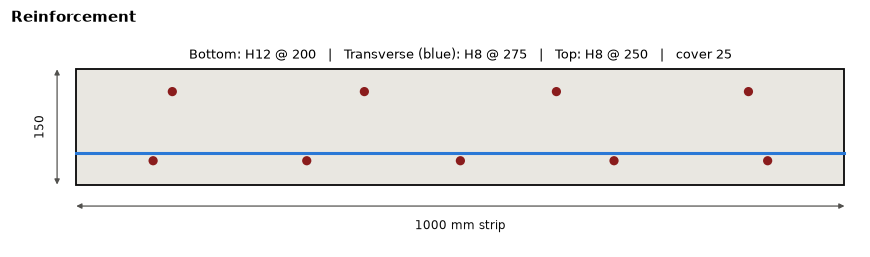

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| fire – slab thickness | EN 1992-1-2 5.7 | 0.53 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 5.7 | 0.65 | ✅ PASS |
| singly reinforced | EC2 5.5(4) | 0.32 | ✅ PASS |
| area provided main bottom | EC2 6.1, 9.3.1.1 | 0.81 | ✅ PASS |
| maximum spacing main bottom | EC2 9.3.1.1(3) | 0.80 | ✅ PASS |
| maximum steel main bottom | EC2 9.2.1.1(3) | 0.09 | ✅ PASS |
| shear, no links needed | EC2 6.2.1(3), 6.2.1(4) | 0.37 | ✅ PASS |
| deflection (span/depth) | EC2 7.4.2 | 0.92 | ✅ PASS |
| crack control | EC2 7.3.3(1) | – | ✅ PASS |
| area provided secondary bottom | EC2 6.1, 9.3.1.1 | 0.98 | ✅ PASS |
| maximum spacing secondary bottom | EC2 9.3.1.1(3) | 0.69 | ✅ PASS |
| maximum steel secondary bottom | EC2 9.2.1.1(3) | 0.03 | ✅ PASS |
| singly reinforced (partial fixity) | EC2 5.5(4) | 0.05 | ✅ PASS |
| area provided top at supports | EC2 6.1, 9.3.1.1 | 0.89 | ✅ PASS |
| maximum spacing top at supports | EC2 9.3.1.1(3) | 1.00 | ✅ PASS |
| maximum steel top at supports | EC2 9.2.1.1(3) | 0.03 | ✅ PASS |
| anchorage at the support | EC2 9.2.1.4(3) | 0.44 | ✅ PASS |

**All checks pass.**

In [8]:
s.let("A_s_main", Ap, "mm²/m")
s.calc("A_s_req", "max(0.2*A_s_main, A_s_min)", "mm²/m", "EC2 9.3.1.1(2), 9.2.1.1(1)", "Secondary steel (20% of main; the minimum is also kept)")
p2, s2 = D.pick_slab(s["A_s_req"], h, main=False, phis=(8, 10))
D.slab_bars(s, p2, s2, h, main=False, label="secondary bottom")
s.calc("M_top", "0.15*M_span", "kN·m/m", "EC2 9.3.1.2(2), end support", "Top moment if the wall gives partial fixity"); s.show("Secondary reinforcement")
At, _ = D.flexure(s, s["M_top"], 1000, d, label="(partial fixity)")
pt, st = D.pick_slab(s["A_s_req"], h, phis=(8, 10))
D.slab_bars(s, pt, st, h, label="top at supports")
s.calc("l_top", "0.2*l_n", "mm", "EC2 9.3.1.2(2)", "Minimum extension from the face of the support"); s.show("Top steel at supports")
s.let("a_l", d, "mm", "Shift, members without shear reinforcement", "EC2 9.2.1.3(2)")
s.let("V_Ed", s["V_sup"], "kN/m"); s.calc("z", "0.9*d", "mm")
s.calc("F_E", "V_Ed*a_l/z", "kN/m", "EC2 Exp. (9.3), N_Ed = 0", "Tensile force to anchor")
s.let("A_s_prov", Ap / 2, "mm²/m", "Half the span steel"); s.calc("sigma_E", "F_E*1000/A_s_prov", "N/mm²")
l = D.anchorage(s, phi, s["sigma_E"])
s.calc("l_avail", "t - c_nom", "mm", "", "Length available past the face of the support")
s.check("l_avail", ">=", "l_bd", "anchorage at the support", "EC2 9.2.1.4(3)"); s.show("Anchorage of bottom bars")
P.slab_section(h, c, (phi, spacing), (pt, st), (p2, s2), "Reinforcement")
s.summary()